In [96]:
from sklearn.datasets import load_iris
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score , confusion_matrix, classification_report, silhouette_score


datf = load_iris(as_frame = True)
df = datf.frame
print(df.columns)
print(df.head())

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='object')
   sepal length (cm)  sepal width (cm)  ...  petal width (cm)  target
0                5.1               3.5  ...               0.2       0
1                4.9               3.0  ...               0.2       0
2                4.7               3.2  ...               0.2       0
3                4.6               3.1  ...               0.2       0
4                5.0               3.6  ...               0.2       0

[5 rows x 5 columns]


In [97]:
X = datf.data
y = datf.target
print(X.head())
print(y.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [99]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [105]:
kmeans = KMeans(
    n_clusters = 3,
    random_state = 42,
    n_init = 10
)
clusters = kmeans.fit_predict(X_scaled)

print("cluster labels")
print(clusters)

print("\nactual species:")
print(y)

print(silhouette_score(X_scaled , clusters))

cluster labels
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]

actual species:
0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: target, Length: 150, dtype: int64
0.45994823920518646


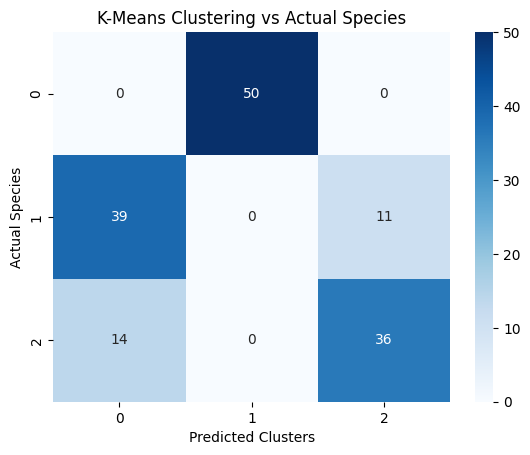

In [102]:
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y,clusters)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Clusters")
plt.ylabel("Actual Species")
plt.title("K-Means Clustering vs Actual Species")
plt.show()

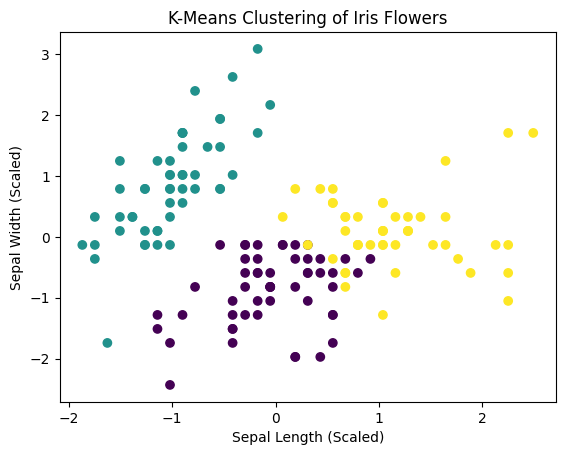

In [103]:
# Visualize clusters using first two features
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=clusters, cmap='viridis')

plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")
plt.title("K-Means Clustering of Iris Flowers")
plt.show()